In [1]:
import os
os.environ['CUBLAS_WORKSPACE_CONFIG'] = ':4096:8'
import random
import numpy as np
import pandas as pd
import torch

from melanoma_cls.config import DATA_DIR, MODELS_DIR
from melanoma_cls.plots import plot_one_image, viz_batch_transform, generate_val_report, generate_test_report, generate_test_gradcam
from melanoma_cls.dataset import ISICDataset, PH2Dataset, create_ph2_metadata, train_transform, val_transform, test_transform
from melanoma_cls.modeling.train import staged_ft_loop
from melanoma_cls.modeling.predict import eval_model
from kagglehub import dataset_download
from IPython.display import display
from torch.utils.data import DataLoader

SEED = 0

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
torch.use_deterministic_algorithms(True, warn_only=True)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(DEVICE)

c:\Users\Admin\Desktop\Course_Materials\melanoma_classification\melanoma_cls_venv\Lib\site-packages\torchvision\transforms\v2\_deprecated.py:42: UserWarning: The transform `ToTensor()` is deprecated and will be removed in a future release. Instead, please use `v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True)])`.Output is equivalent up to float precision.
  warnings.warn(


cuda


# Data Loading and EDA

In [2]:
DATA_CACHE = DATA_DIR / 'isic2020-224'
DATA_CACHE.mkdir(exist_ok=True)
data_path = dataset_download('nischaydnk/isic-2020-jpg-224x224-resized', output_dir=DATA_CACHE)
train_images = DATA_CACHE / 'train-image' / 'image'
all_images = [f.name.lower() for f in train_images.iterdir() if f.is_file()]
all_ext = [name.split('.')[-1] for name in all_images] # all .jpg ext

assert (len(all_images) == 33126) and (len(all_ext) == 33126) and all(ext == 'jpg' for ext in all_ext) # 33126 all training images are .jpg format

In [3]:
'''
each row in meta_df is represented by a patient_id, associated to its corresponding isic image id and target label for that image
1 patient can contribute MULTIPLE rows of examples, superficial EDA seems to suggest that all images share the same target (but confirm with a more rigorous check)
no missing values across the entire training metadata (but still need to check if all images are present within train_images)
'''
meta_df = pd.read_csv(DATA_CACHE / 'train-metadata.csv', sep=',', index_col=0)

assert set(meta_df['isic_id'].str.lower()) == set([name[:-4] for name in all_images]) # images are present for all unique isic_id found in meta_df
assert meta_df.isna().any().any() == False # has no NAs across the entire training metadata
assert meta_df['isic_id'].duplicated().any() == False # no duplicated isic_id

freq = meta_df['target'].value_counts()
display(meta_df.head(10))
print(f'ISIC Metadata Dims: {meta_df.shape}') # (33126, 3)
display(meta_df['target'].value_counts()) # 32542 benign, 584 malignant, extreme class imbalance only 1.76% are malignant

,isic_id,patient_id,target
0,ISIC_2637011,IP_7279968,0
1,ISIC_0015719,IP_3075186,0
2,ISIC_0052212,IP_2842074,0
3,ISIC_0068279,IP_6890425,0
4,ISIC_0074268,IP_8723313,0
5,ISIC_0074311,IP_2950485,0
6,ISIC_0074542,IP_4698288,0
7,ISIC_0075663,IP_6017204,0
8,ISIC_0075914,IP_7622888,0
9,ISIC_0076262,IP_5075533,0


ISIC Metadata Dims: (33126, 3)


target
0    32542
1      584
Name: count, dtype: int64

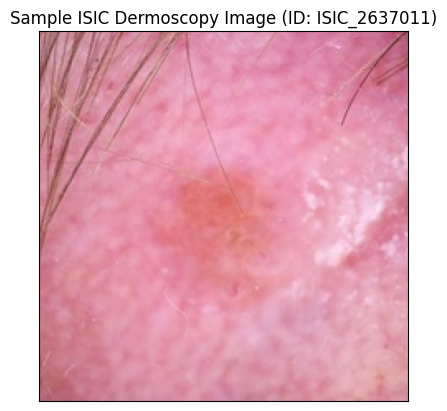

In [4]:
plot_one_image(meta_df, train_images)

In [5]:
patient_id_tgts = meta_df.groupby('patient_id')['target'].agg(['nunique', 'count'])
display(patient_id_tgts.head(10))
display(patient_id_tgts['nunique'].value_counts()) # nunique has two distinct values 1 and 2 corresponding to binary classes. some patient_id contribute multiple samples with different labels!

,nunique,count
patient_id,,
IP_0001230,1,6
IP_0019713,1,13
IP_0036322,1,5
IP_0038436,1,3
IP_0038545,2,28
IP_0039318,1,39
IP_0041255,1,18
IP_0045462,1,4
IP_0046310,1,7


nunique
1    1629
2     427
Name: count, dtype: int64

In [6]:
PH2_CACHE = DATA_DIR / 'ph2_cache'
PH2_CACHE.mkdir(exist_ok=True)
ph2_path = dataset_download('spacesurfer/ph2-dataset', output_dir=PH2_CACHE) # external image test set
ph2_metadata_path = PH2_CACHE / 'PH2Dataset/ph2_metadata.csv'
ph2_txt_path = PH2_CACHE / 'PH2Dataset/PH2_dataset.txt'
ph2_meta = create_ph2_metadata(ph2_metadata_path, ph2_txt_path)

(200, 10)


In [7]:
'''
Legends for Clinical Diagnosis: 
0 - Common Nevus;
1 - Atypical Nevus;
2 - Melanoma.
'''
assert ph2_meta[['Name', 'Clinical Diagnosis']].isna().any().any() == False # no NaNs
display(ph2_meta['Clinical Diagnosis'].value_counts()) # 0: 80, 1: 80, 2: 40; matching expectation
ph2_meta['labels'] = ph2_meta['Clinical Diagnosis'] == 2
ph2_df = ph2_meta[['Name', 'labels']].copy()

ph2_img_path = PH2_CACHE / 'PH2Dataset/PH2 Dataset images'
assert set(ph2_df['Name']) == set([folder.stem for folder in ph2_img_path.rglob('*/*_Dermoscopic_Image/*.bmp')]) # all image names map to subdirectory within ph2_cache with their corresponding .bmp image
assert len(set([folder.name for folder in ph2_img_path.rglob('*/*_Dermoscopic_Image/*.bmp')])) == 200 # 200 as expected

Clinical Diagnosis
0    80
1    80
2    40
Name: count, dtype: int64

# Visualizing Transformation Pipeline

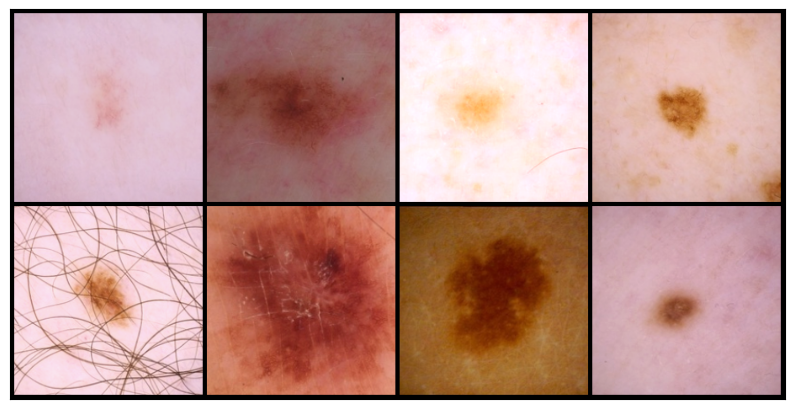

In [8]:
viz_dataset = ISICDataset(meta_df, train_images, transform=train_transform)
viz_loader = DataLoader(viz_dataset, batch_size=8, shuffle=True)
viz_batch_transform(viz_loader)

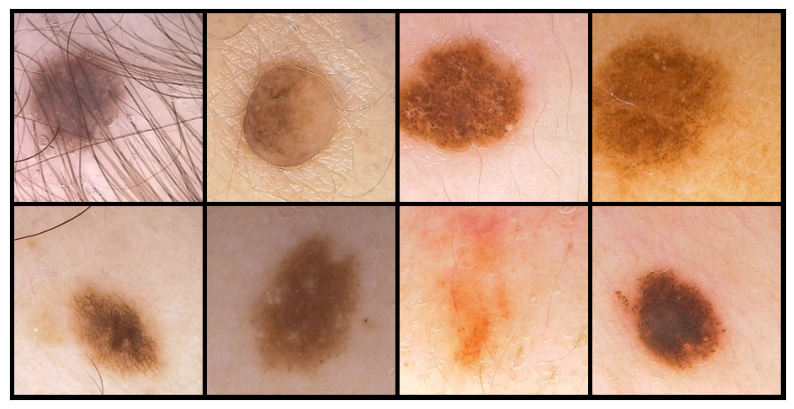

In [9]:
test_viz_dataset = PH2Dataset(ph2_df, ph2_img_path, transform=test_transform)
test_viz_loader = DataLoader(test_viz_dataset, batch_size=8, shuffle=False)
viz_batch_transform(test_viz_loader)

# ResNet50

In [10]:
EPOCHS = 15 # 12 epochs, ~1h to complete
BATCH_SIZE = 64
N_SPLITS = 5

fold_state_dict = staged_ft_loop(meta_df, train_transform, val_transform, train_images, EPOCHS, BATCH_SIZE, SEED, DEVICE, MODELS_DIR, 'resnet', N_SPLITS)
generate_val_report(fold_state_dict)

[FOLD]: 0it [00:00, ?it/s]

Fold 1 Start

[STAGE 1] Epoch 1:
	Train Loss: 0.527
	Val Loss: 0.843
	AUPRC: 0.087

[STAGE 1] Epoch 4:
	Train Loss: 0.429
	Val Loss: 0.707
	AUPRC: 0.105

[STAGE 1] Epoch 8:
	Train Loss: 0.395
	Val Loss: 0.430
	AUPRC: 0.116

[STAGE 1] Epoch 12:
	Train Loss: 0.389
	Val Loss: 0.543
	AUPRC: 0.121

[STAGE 1] Epoch 15:
	Train Loss: 0.383
	Val Loss: 0.317
	AUPRC: 0.104

[STAGE 2] Epoch 1:
	Train Loss: 0.459
	Val Loss: 0.490
	AUPRC: 0.079

[STAGE 2] Epoch 4:
	Train Loss: 0.229
	Val Loss: 0.228
	AUPRC: 0.097

[STAGE 2] Epoch 8:
	Train Loss: 0.138
	Val Loss: 0.254
	AUPRC: 0.144

[STAGE 2] Epoch 12:
	Train Loss: 0.112
	Val Loss: 0.197
	AUPRC: 0.094

[STAGE 2] Epoch 15:
	Train Loss: 0.065
	Val Loss: 0.176
	AUPRC: 0.118

Fold 2 Start

[STAGE 1] Epoch 1:
	Train Loss: 0.524
	Val Loss: 0.671
	AUPRC: 0.120

[STAGE 1] Epoch 4:
	Train Loss: 0.447
	Val Loss: 0.365
	AUPRC: 0.145

[STAGE 1] Epoch 8:
	Train Loss: 0.417
	Val Loss: 0.389
	AUPRC: 0.159

[STAGE 1] Epoch 12:
	Train Loss: 0.397
	Val Loss: 0.489
	A

In [11]:
fold_eval_dict, test_true = eval_model(ph2_df, fold_state_dict, test_transform, ph2_img_path, DEVICE, BATCH_SIZE)
generate_test_report(fold_eval_dict, test_true)

[FOLD 1]:
	Test AUROC: 0.863
	Test AUPRC: 0.691

[FOLD 2]:
	Test AUROC: 0.833
	Test AUPRC: 0.631

[FOLD 3]:
	Test AUROC: 0.846
	Test AUPRC: 0.656

[FOLD 4]:
	Test AUROC: 0.880
	Test AUPRC: 0.714

[FOLD 5]:
	Test AUROC: 0.744
	Test AUPRC: 0.468

[ENSEMBLE AVERAGE]
	Test AUROC: 0.859
	Test AUPRC: 0.642


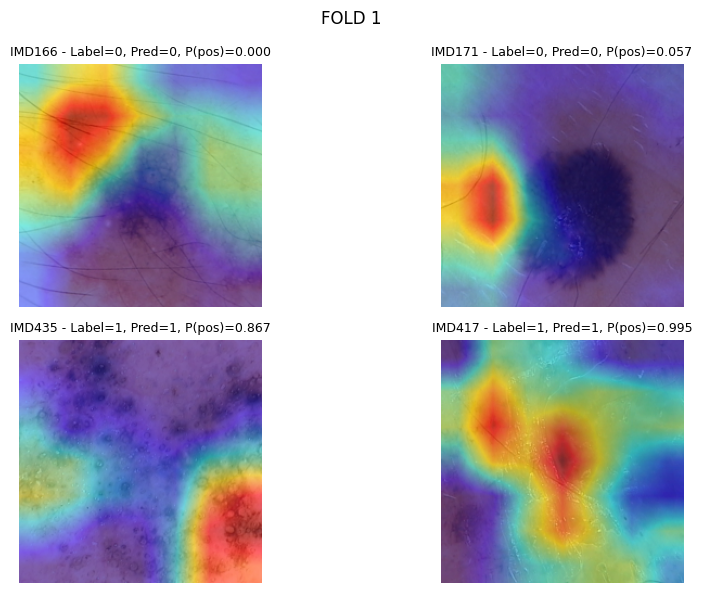

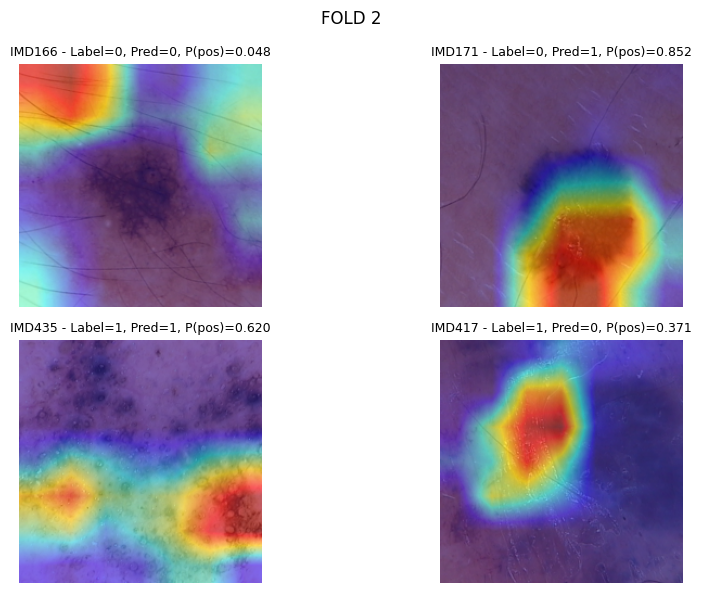

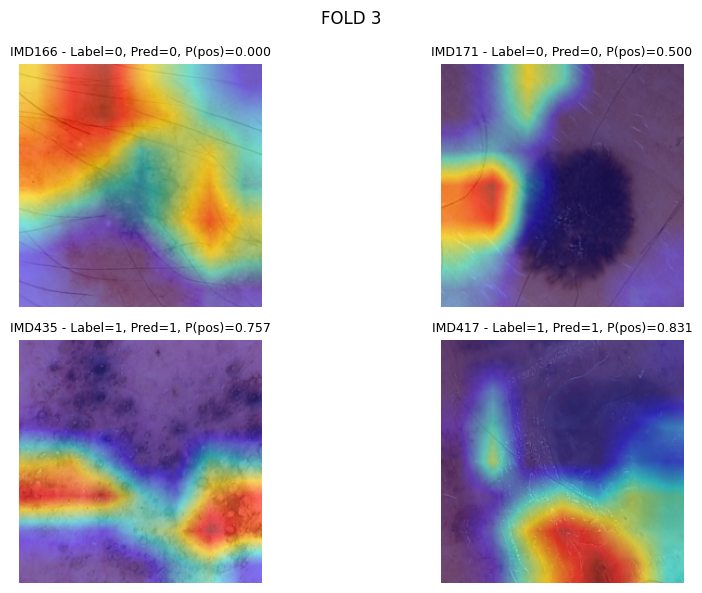

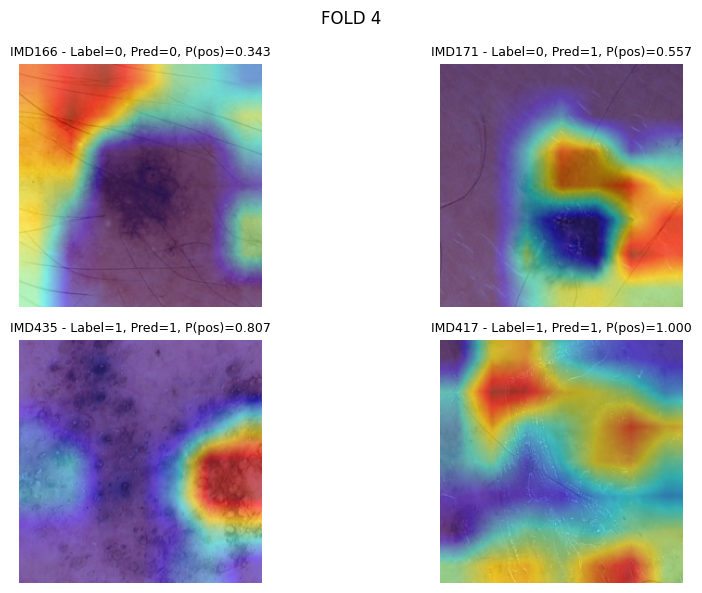

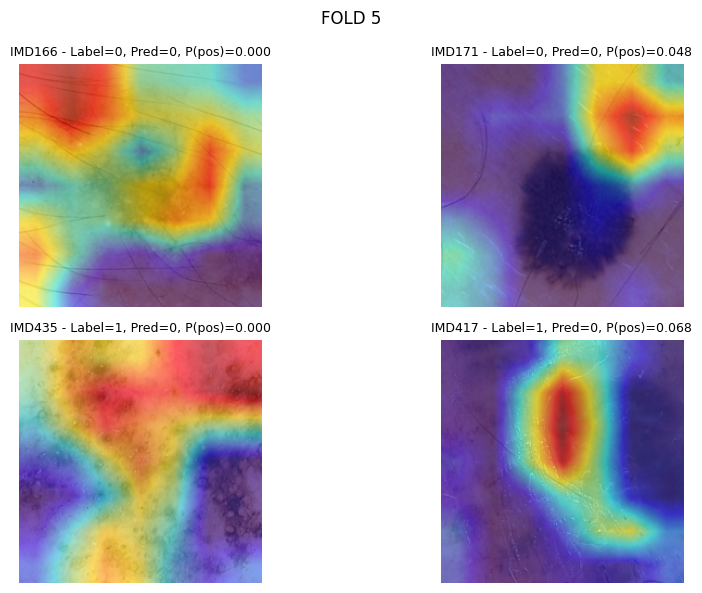

In [12]:
generate_test_gradcam(ph2_df, ph2_img_path, fold_state_dict, test_transform, SEED, DEVICE, 'resnet')

# DenseNet121

In [13]:
densenet_fold_state_dict = staged_ft_loop(meta_df, train_transform, val_transform, train_images, EPOCHS, BATCH_SIZE, SEED, DEVICE, MODELS_DIR, 'densenet', N_SPLITS)
generate_val_report(densenet_fold_state_dict)

[FOLD]: 0it [00:00, ?it/s]

Fold 1 Start

[STAGE 1] Epoch 1:
	Train Loss: 0.515
	Val Loss: 0.547
	AUPRC: 0.085

[STAGE 1] Epoch 4:
	Train Loss: 0.433
	Val Loss: 0.499
	AUPRC: 0.096

[STAGE 1] Epoch 8:
	Train Loss: 0.395
	Val Loss: 0.334
	AUPRC: 0.090

[STAGE 1] Epoch 12:
	Train Loss: 0.397
	Val Loss: 0.426
	AUPRC: 0.079

[STAGE 1] Epoch 15:
	Train Loss: 0.396
	Val Loss: 0.342
	AUPRC: 0.089

[STAGE 2] Epoch 1:
	Train Loss: 0.430
	Val Loss: 0.399
	AUPRC: 0.089

[STAGE 2] Epoch 4:
	Train Loss: 0.241
	Val Loss: 0.222
	AUPRC: 0.091

[STAGE 2] Epoch 8:
	Train Loss: 0.151
	Val Loss: 0.177
	AUPRC: 0.106

[STAGE 2] Epoch 12:
	Train Loss: 0.120
	Val Loss: 0.178
	AUPRC: 0.086

[STAGE 2] Epoch 15:
	Train Loss: 0.084
	Val Loss: 0.142
	AUPRC: 0.101

Fold 2 Start

[STAGE 1] Epoch 1:
	Train Loss: 0.553
	Val Loss: 0.543
	AUPRC: 0.098

[STAGE 1] Epoch 4:
	Train Loss: 0.443
	Val Loss: 0.332
	AUPRC: 0.121

[STAGE 1] Epoch 8:
	Train Loss: 0.421
	Val Loss: 0.448
	AUPRC: 0.117

[STAGE 1] Epoch 12:
	Train Loss: 0.415
	Val Loss: 0.396
	A

In [14]:
densenet_fold_eval_dict, densenet_test_true = eval_model(ph2_df, densenet_fold_state_dict, test_transform, ph2_img_path, DEVICE, BATCH_SIZE)
generate_test_report(densenet_fold_eval_dict, densenet_test_true)

[FOLD 1]:
	Test AUROC: 0.815
	Test AUPRC: 0.480

[FOLD 2]:
	Test AUROC: 0.810
	Test AUPRC: 0.544

[FOLD 3]:
	Test AUROC: 0.801
	Test AUPRC: 0.505

[FOLD 4]:
	Test AUROC: 0.802
	Test AUPRC: 0.577

[FOLD 5]:
	Test AUROC: 0.819
	Test AUPRC: 0.580

[ENSEMBLE AVERAGE]
	Test AUROC: 0.848
	Test AUPRC: 0.577


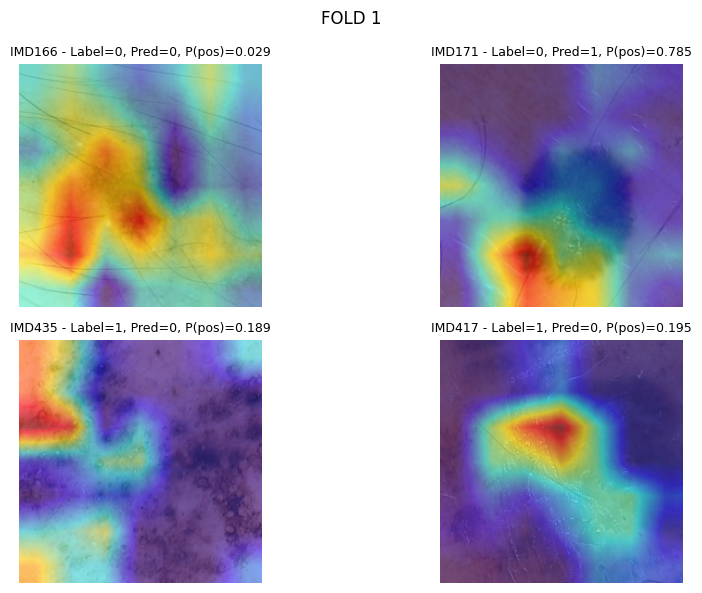

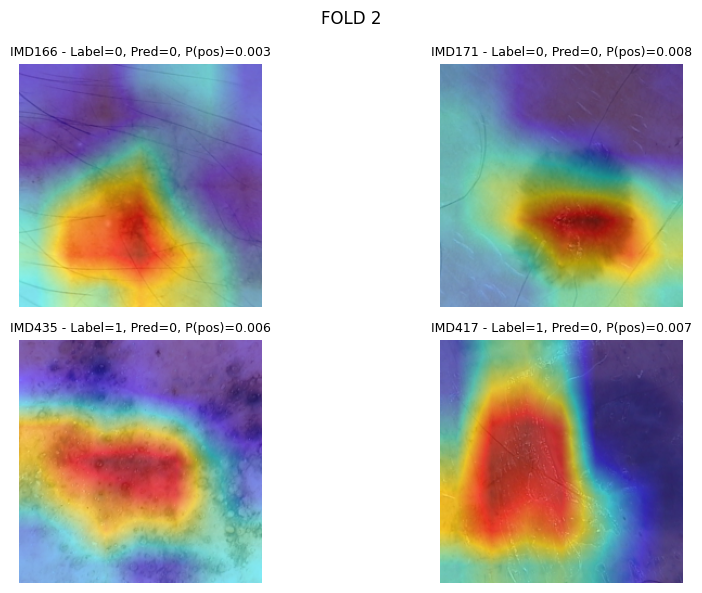

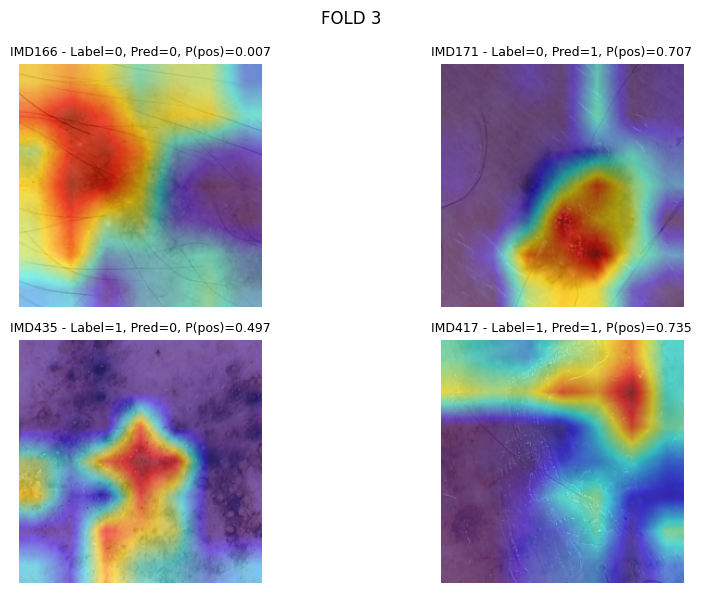

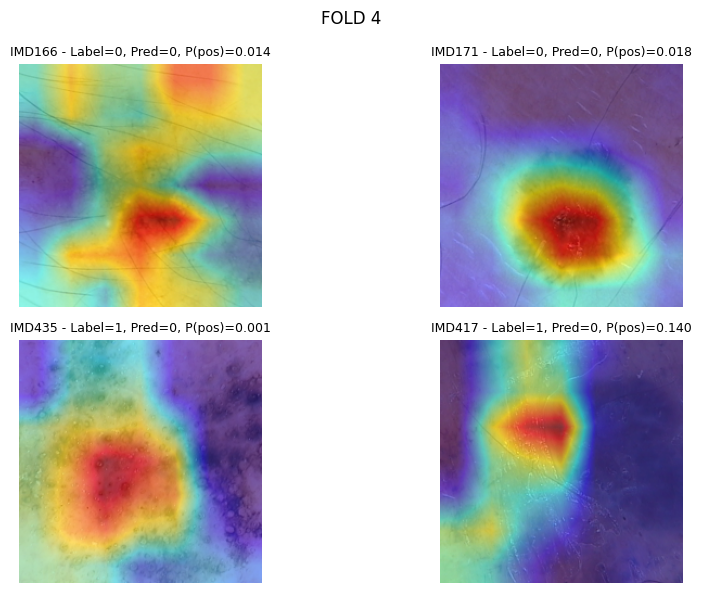

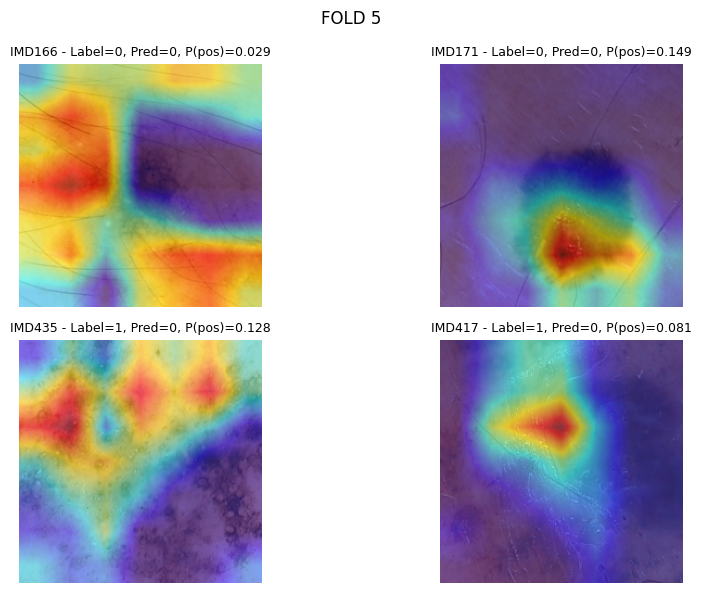

In [15]:
generate_test_gradcam(ph2_df, ph2_img_path, densenet_fold_state_dict, test_transform, SEED, DEVICE, 'densenet')

# Swin Transformer

In [16]:
swin_fold_state_dict = staged_ft_loop(meta_df, train_transform, val_transform, train_images, EPOCHS, BATCH_SIZE, SEED, DEVICE, MODELS_DIR, 'swin', N_SPLITS)
generate_val_report(swin_fold_state_dict)

[FOLD]: 0it [00:00, ?it/s]

Fold 1 Start

[STAGE 1] Epoch 1:
	Train Loss: 0.521
	Val Loss: 0.652
	AUPRC: 0.099

[STAGE 1] Epoch 4:
	Train Loss: 0.424
	Val Loss: 0.599
	AUPRC: 0.107

[STAGE 1] Epoch 8:
	Train Loss: 0.390
	Val Loss: 0.401
	AUPRC: 0.103

[STAGE 1] Epoch 12:
	Train Loss: 0.387
	Val Loss: 0.563
	AUPRC: 0.100

[STAGE 1] Epoch 15:
	Train Loss: 0.390
	Val Loss: 0.530
	AUPRC: 0.104

[STAGE 2] Epoch 1:
	Train Loss: 0.422
	Val Loss: 0.534
	AUPRC: 0.101

[STAGE 2] Epoch 4:
	Train Loss: 0.299
	Val Loss: 0.416
	AUPRC: 0.090

[STAGE 2] Epoch 8:
	Train Loss: 0.214
	Val Loss: 0.246
	AUPRC: 0.118

[STAGE 2] Epoch 12:
	Train Loss: 0.170
	Val Loss: 0.211
	AUPRC: 0.102

[STAGE 2] Epoch 15:
	Train Loss: 0.148
	Val Loss: 0.227
	AUPRC: 0.104

Fold 2 Start

[STAGE 1] Epoch 1:
	Train Loss: 0.529
	Val Loss: 0.730
	AUPRC: 0.094

[STAGE 1] Epoch 4:
	Train Loss: 0.438
	Val Loss: 0.577
	AUPRC: 0.115

[STAGE 1] Epoch 8:
	Train Loss: 0.424
	Val Loss: 0.496
	AUPRC: 0.114

[STAGE 1] Epoch 12:
	Train Loss: 0.403
	Val Loss: 0.442
	A

In [17]:
swin_fold_eval_dict, swin_test_true = eval_model(ph2_df, swin_fold_state_dict, test_transform, ph2_img_path, DEVICE, BATCH_SIZE)
generate_test_report(swin_fold_eval_dict, swin_test_true)

[FOLD 1]:
	Test AUROC: 0.832
	Test AUPRC: 0.514

[FOLD 2]:
	Test AUROC: 0.776
	Test AUPRC: 0.506

[FOLD 3]:
	Test AUROC: 0.764
	Test AUPRC: 0.518

[FOLD 4]:
	Test AUROC: 0.794
	Test AUPRC: 0.490

[FOLD 5]:
	Test AUROC: 0.850
	Test AUPRC: 0.633

[ENSEMBLE AVERAGE]
	Test AUROC: 0.841
	Test AUPRC: 0.570


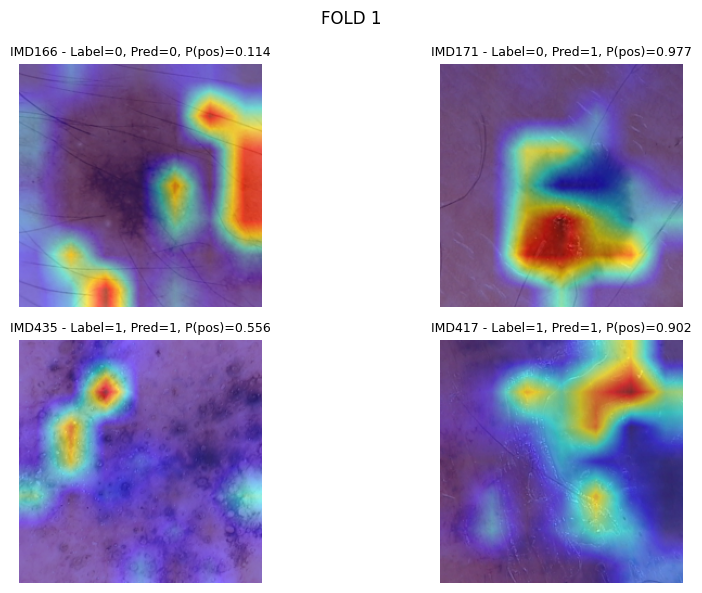

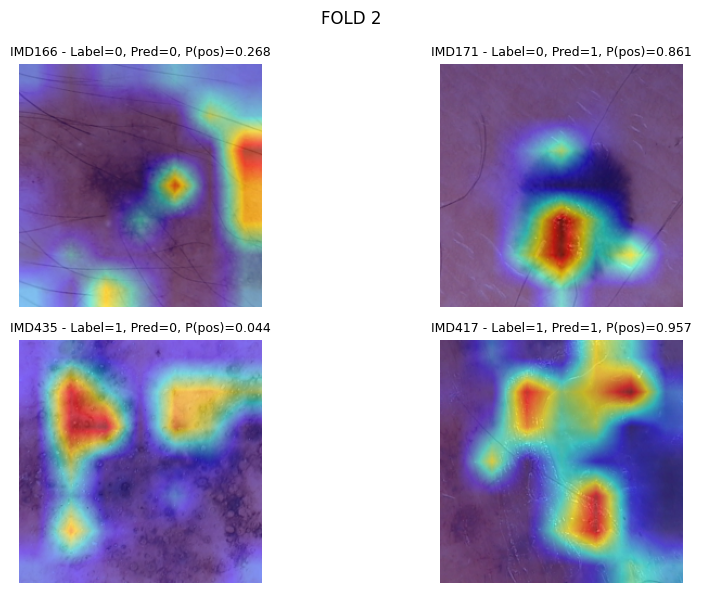

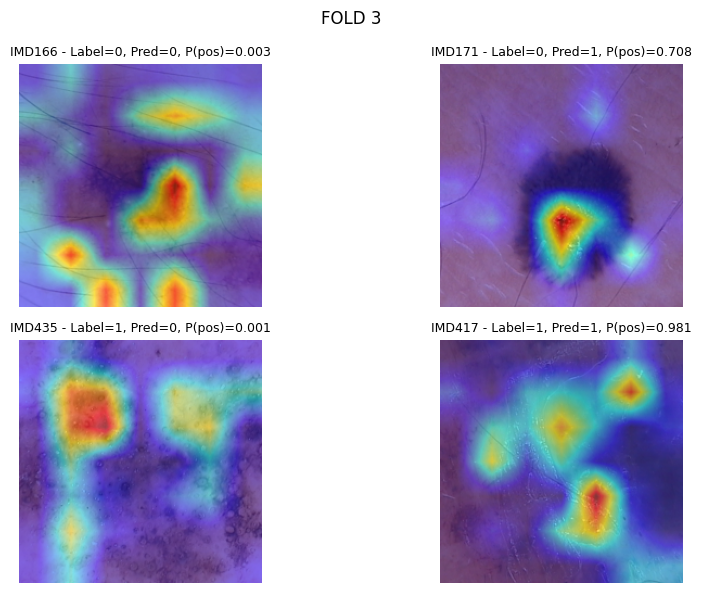

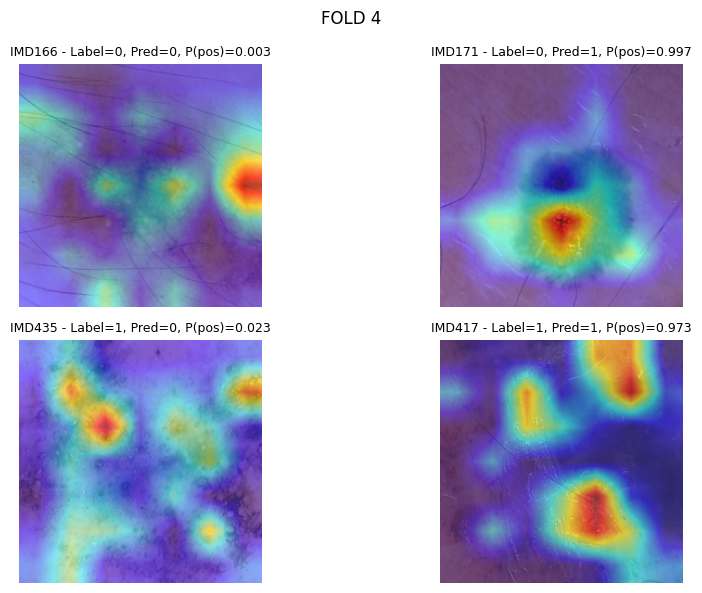

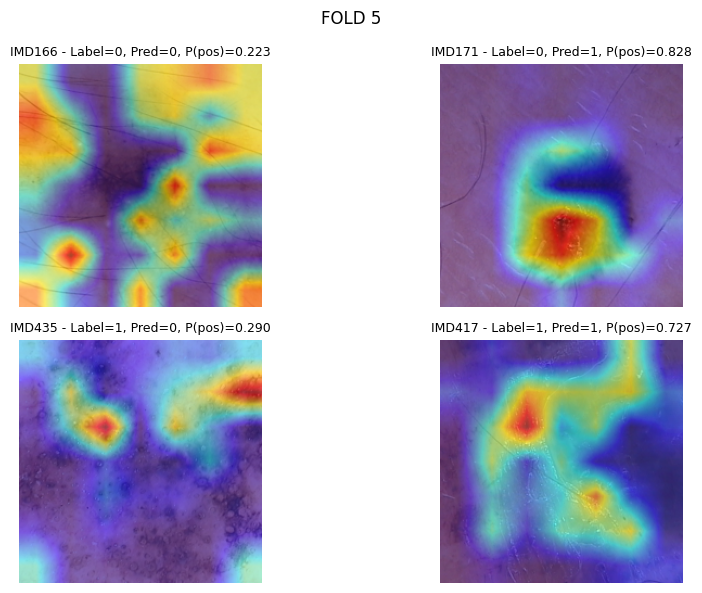

In [18]:
generate_test_gradcam(ph2_df, ph2_img_path, swin_fold_state_dict, test_transform, SEED, DEVICE, 'swin')